In [ ]:
!pip install opencv-python matplotlib numpy

Keypoints in original image: 1000
Keypoints in rotated image: 1000
Total matches: 1000


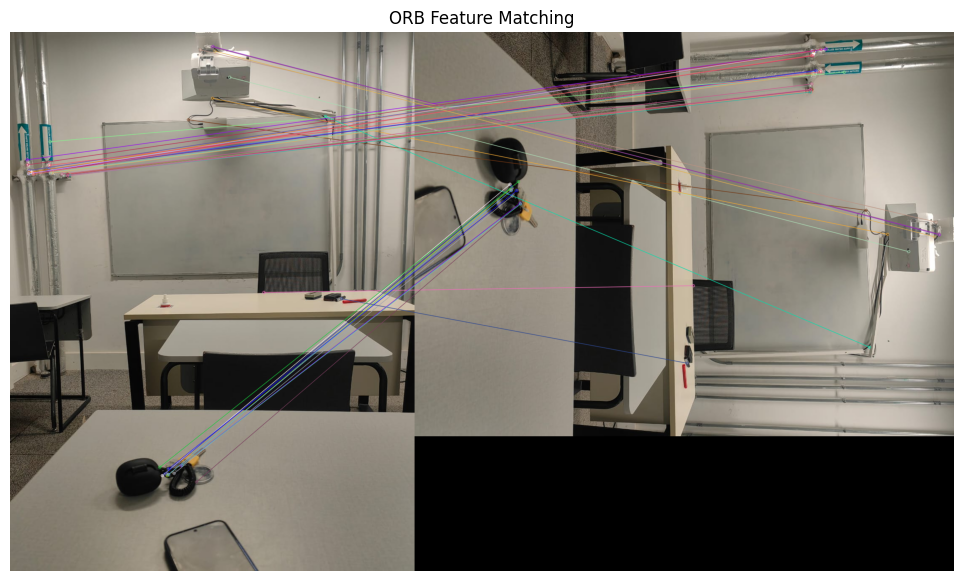

In [ ]:

import cv2
import matplotlib.pyplot as plt

# STEP 1: Load and rotate the image
image1 = cv2.imread("/content/classroom.jpeg")

image2 = cv2.rotate(image1, cv2.ROTATE_90_CLOCKWISE)

# Convert both images to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)


# STEP 2: Detect keypoints and descriptors using ORB
orb = cv2.ORB_create(nfeatures=1000)

kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

print("Keypoints in original image:", len(kp1))
print("Keypoints in rotated image:", len(kp2))


# STEP 3: Match descriptors using BFMatcher
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

matches = bf.match(des1, des2)

# Sort matches by distance (smallest first)
matches = sorted(matches, key=lambda x: x.distance)

print("Total matches:", len(matches))


# STEP 4: Display the matching results
result = cv2.drawMatches(
    image1, kp1,
    image2, kp2,
    matches[:40],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("ORB Feature Matching")
plt.axis("off")
plt.show()
